## DETECTOR DE ALCOHOL PYTHON!


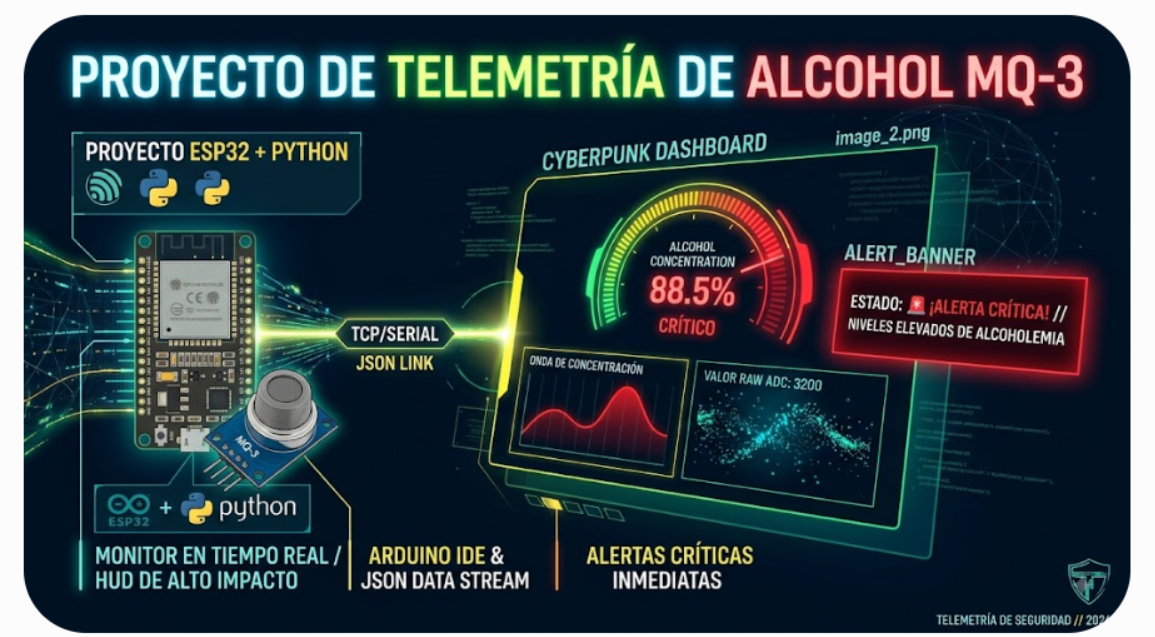

## CONEXIONES

)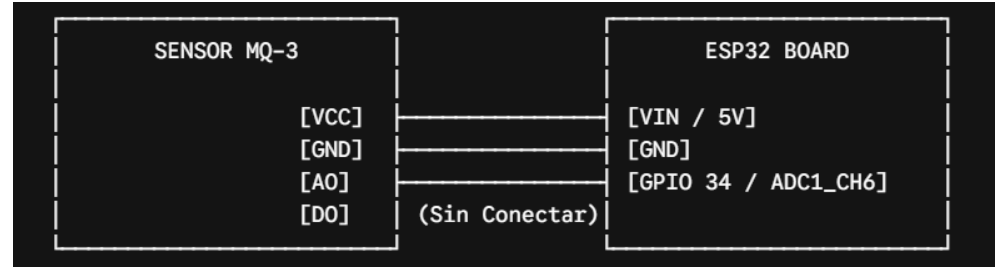

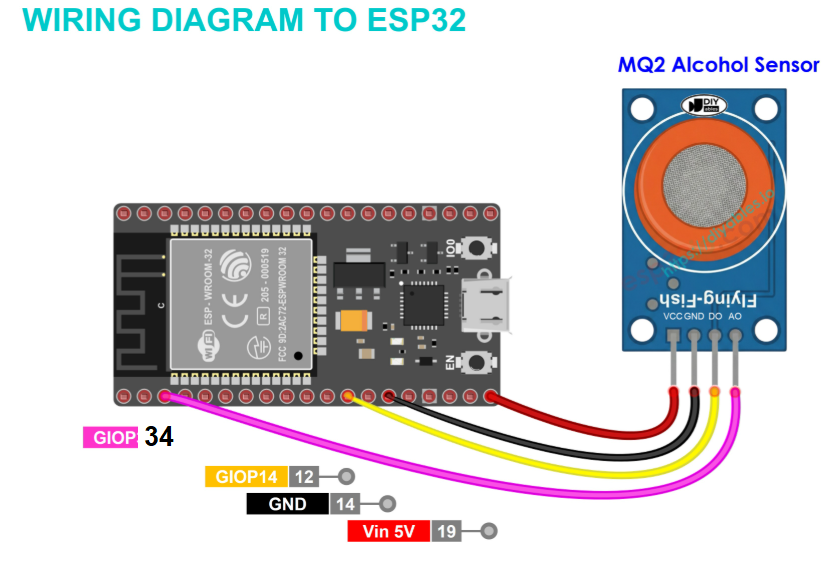

## ARDUINO IDE

In [1]:
/*
  ==============================================================
  MONITOR DE ALCOHOLEMIA MQ-3 + BUZZER - ESP32
  ==============================================================
  Conexiones:
    MQ-3  AO  -> GPIO 34      MQ-3 VCC -> VIN (5V)   MQ-3 GND -> GND
    Buzzer +  -> GPIO 26      Buzzer - -> GND

  El buzzer pita de forma intermitente cuando la concentración
  supera UMBRAL_ALERTA. Desde Python se puede silenciar:
    "M" -> silenciar      "U" -> reactivar
*/

const int MQ3_PIN = 34;          // Pin ADC del ESP32 (GPIO 34)
const int BUZZER_PIN = 26;       // Pin del buzzer
const bool BUZZER_PASIVO = false; // false = buzzer activo; true = pasivo (necesita tono)
const int SAMPLES = 15;          // Muestras para suavizado de señal

// Calibración: ajusta AIRE_LIMPIO al valor ADC que marca el sensor
// ya caliente (2-5 min) y sin alcohol cerca.
const int AIRE_LIMPIO = 300;
const int SATURACION = 3200;
const float UMBRAL_ALERTA = 50.0; // % a partir del cual suena el buzzer

bool silenciado = false;

void buzzer(bool encendido) {
  if (BUZZER_PASIVO) {
    if (encendido) tone(BUZZER_PIN, 2000);
    else noTone(BUZZER_PIN);
  } else {
    digitalWrite(BUZZER_PIN, encendido ? HIGH : LOW);
  }
}

void leerComandos() {
  while (Serial.available()) {
    char c = toupper(Serial.read());
    if (c == 'M') silenciado = true;
    else if (c == 'U') silenciado = false;
  }
}

void setup() {
  Serial.begin(115200);
  analogReadResolution(12);   // Resolución de 12 bits (0 a 4095)
  pinMode(MQ3_PIN, INPUT);
  pinMode(BUZZER_PIN, OUTPUT);
  buzzer(false);
}

void loop() {
  leerComandos();

  // Lectura filtrada (Media Móvil para eliminar ruido eléctrico)
  long sum = 0;
  for (int i = 0; i < SAMPLES; i++) {
    sum += analogRead(MQ3_PIN);
    delay(2);
  }
  int rawValue = sum / SAMPLES;

  // Conversión a porcentaje aproximado (0% - 100%)
  float percentage = (rawValue - AIRE_LIMPIO) * 100.0 / (SATURACION - AIRE_LIMPIO);
  percentage = constrain(percentage, 0.0, 100.0);

  // Buzzer intermitente (250 ms encendido / 250 ms apagado) mientras haya alerta
  bool alerta = percentage >= UMBRAL_ALERTA;
  bool pitar = alerta && !silenciado && ((millis() / 250) % 2 == 0);
  buzzer(pitar);

  // Formato JSON para la interfaz Python
  Serial.print("{\"raw\":");
  Serial.print(rawValue);
  Serial.print(",\"percent\":");
  Serial.print(percentage, 1);
  Serial.print(",\"alert\":");
  Serial.print(alerta ? 1 : 0);
  Serial.print(",\"mute\":");
  Serial.print(silenciado ? 1 : 0);
  Serial.println("}");

  delay(50); // ~20 actualizaciones por segundo
}

IndentationError: unexpected indent (3908808822.py, line 2)

## PYHTON

In [ ]:
import tkinter as tk
import json
import serial
import serial.tools.list_ports
import threading
import time
from collections import deque

# --- CONFIGURACIÓN DE COLORES HUD (ESTILO CYBERPUNK) ---
BG_COLOR = "#080c14"       # Fondo Oscuro Profundo
PANEL_BG = "#0f172a"       # Fondo Paneles
NEON_GREEN = "#00ffcc"     # Estado Seguro
NEON_YELLOW = "#ffcc00"    # Estado Precaución
NEON_RED = "#ff0055"       # Estado Alerta Crítica
GRID_COLOR = "#1e293b"      # Rejilla de Fondo
TEXT_COLOR = "#e2e8f0"     # Texto principal

class CyberpunkDashboard:
    def __init__(self, root):
        self.root = root
        self.root.title("TELEMETRÍA // MONITOR DE ALCOHOL MQ-3")
        self.root.geometry("900x650")
        self.root.configure(bg=BG_COLOR)

        self.current_percent = 0.0
        self.current_raw = 0
        self.alerta = False        # el ESP32 indica si se superó el umbral
        self.silenciado = False    # el ESP32 confirma si el buzzer está silenciado
        self.history = deque(maxlen=80)
        for _ in range(80): 
            self.history.append(0)

        # Variables de estado del puerto COM (Thread-Safe)
        self.status_text = "BUSCANDO ESP32..."
        self.status_color = NEON_YELLOW

        self.serial_port = None
        self.running = True

        self.setup_ui()
        self.auto_connect_serial()

        # Bucle principal de renderizado gráfico (60 FPS)
        self.animate()

    def setup_ui(self):
        # Header / Encabezado
        header = tk.Frame(self.root, bg=PANEL_BG, height=50)
        header.pack(fill="x", padx=10, pady=10)
        
        lbl_title = tk.Label(header, text="🛡️ TELEMETRÍA DE SENSOR MQ-3", 
                             font=("Consolas", 14, "bold"), fg=NEON_GREEN, bg=PANEL_BG)
        lbl_title.pack(side="left", padx=15, pady=10)

        self.lbl_status = tk.Label(header, text=self.status_text, 
                                   font=("Consolas", 10, "bold"), fg=self.status_color, bg=PANEL_BG)
        self.lbl_status.pack(side="right", padx=15)

        self.btn_mute = tk.Button(header, text="🔇 SILENCIAR BUZZER", font=("Consolas", 10, "bold"),
                                  fg=BG_COLOR, bg=NEON_YELLOW, activebackground=NEON_GREEN,
                                  relief="flat", cursor="hand2", command=self.toggle_mute)
        self.btn_mute.pack(side="right", padx=10, pady=8)

        # Main Layout (Contenedor Split)
        main_frame = tk.Frame(self.root, bg=BG_COLOR)
        main_frame.pack(fill="both", expand=True, padx=10, pady=5)

        # Panel Izquierdo: Tacómetro Radial
        left_panel = tk.Frame(main_frame, bg=PANEL_BG, bd=1, relief="solid")
        left_panel.pack(side="left", fill="both", expand=True, padx=5, pady=5)

        self.gauge_canvas = tk.Canvas(left_panel, width=380, height=340, bg=PANEL_BG, highlightthickness=0)
        self.gauge_canvas.pack(pady=10)

        # Panel Derecho: Gráfica + Valores Raw
        right_panel = tk.Frame(main_frame, bg=PANEL_BG, bd=1, relief="solid")
        right_panel.pack(side="right", fill="both", expand=True, padx=5, pady=5)

        # Display Numérico Raw
        raw_frame = tk.Frame(right_panel, bg=PANEL_BG)
        raw_frame.pack(fill="x", padx=15, pady=15)

        tk.Label(raw_frame, text="VALOR ADC (12-BIT):", font=("Consolas", 10), fg="#64748b", bg=PANEL_BG).pack(anchor="w")
        self.lbl_raw = tk.Label(raw_frame, text="0000", font=("Consolas", 28, "bold"), fg=TEXT_COLOR, bg=PANEL_BG)
        self.lbl_raw.pack(anchor="w")

        self.lbl_buzzer = tk.Label(raw_frame, text="BUZZER: EN ESPERA", font=("Consolas", 11, "bold"),
                                   fg="#64748b", bg=PANEL_BG)
        self.lbl_buzzer.pack(anchor="w", pady=(8, 0))

        # Gráfica de Línea en Tiempo Real
        tk.Label(right_panel, text="ONDA DE CONCENTRACIÓN EN TIEMPO REAL", font=("Consolas", 10, "bold"), fg="#94a3b8", bg=PANEL_BG).pack(anchor="w", padx=15)
        self.graph_canvas = tk.Canvas(right_panel, width=400, height=200, bg="#020617", highlightthickness=1, highlightbackground=GRID_COLOR)
        self.graph_canvas.pack(fill="both", expand=True, padx=15, pady=10)

        # Banner de Alerta Crítica (Inferior)
        self.alert_banner = tk.Label(self.root, text="ESTADO: NORMAL - SIN ALCOHOL DETECTADO", 
                                     font=("Consolas", 12, "bold"), fg=BG_COLOR, bg=NEON_GREEN, height=2)
        self.alert_banner.pack(fill="x", padx=10, pady=10)

    def draw_gauge(self, value):
        self.gauge_canvas.delete("all")
        cx, cy, r = 190, 180, 130

        # Seleccionar color dinámico según el nivel
        if value < 20:
            color = NEON_GREEN
        elif value < 50:
            color = NEON_YELLOW
        else:
            color = NEON_RED

        # Fondo del Arco (240 a -60 grados)
        self.gauge_canvas.create_arc(cx-r, cy-r, cx+r, cy+r, start=-30, extent=240, 
                                     style="arc", outline=GRID_COLOR, width=18)

        # Arco de Valor Dinámico
        extent = -(value / 100.0) * 240
        self.gauge_canvas.create_arc(cx-r, cy-r, cx+r, cy+r, start=210, extent=extent, 
                                     style="arc", outline=color, width=18)

        # Texto Porcentaje Central
        self.gauge_canvas.create_text(cx, cy - 10, text=f"{value:.1f}%", 
                                      font=("Consolas", 36, "bold"), fill=color)
        self.gauge_canvas.create_text(cx, cy + 30, text="CONCENTRACIÓN DE ALCOHOL", 
                                      font=("Consolas", 9, "bold"), fill="#64748b")

    def draw_graph(self):
        self.graph_canvas.delete("all")
        w = self.graph_canvas.winfo_width()
        h = self.graph_canvas.winfo_height()

        if w < 10 or h < 10: 
            return

        # Dibujar Rejilla de Fondo
        for x in range(0, w, 40):
            self.graph_canvas.create_line(x, 0, x, h, fill=GRID_COLOR, dash=(2, 4))
        for y in range(0, h, 30):
            self.graph_canvas.create_line(0, y, w, y, fill=GRID_COLOR, dash=(2, 4))

        # Calcular puntos de la onda
        points = []
        step = w / (len(self.history) - 1)
        for i, val in enumerate(self.history):
            x = i * step
            y = h - ((val / 100.0) * (h - 20) + 10)
            points.append((x, y))

        # Dibujar trayectorias coloreadas
        for i in range(len(points) - 1):
            val = self.history[i]
            color = NEON_GREEN if val < 20 else (NEON_YELLOW if val < 50 else NEON_RED)
            self.graph_canvas.create_line(points[i][0], points[i][1], points[i+1][0], points[i+1][1], 
                                          fill=color, width=2)

    def update_status(self):
        val = self.current_percent
        if val < 20:
            self.alert_banner.config(text="ESTADO: NORMAL // NIVEL DE ALCOHOL SEGURO", bg=NEON_GREEN, fg="#000000")
        elif val < 50:
            self.alert_banner.config(text="⚠️ PRECAUCIÓN // PRESENCIA DE ALCOHOL DETECTADA", bg=NEON_YELLOW, fg="#000000")
        else:
            self.alert_banner.config(text="🚨 ¡ALERTA CRÍTICA! // NIVELES ELEVADOS DE ALCOHOLEMIA", bg=NEON_RED, fg="#ffffff")

        if self.silenciado:
            self.lbl_buzzer.config(text="BUZZER: SILENCIADO 🔇", fg=NEON_YELLOW)
            self.btn_mute.config(text="🔊 ACTIVAR BUZZER", bg=NEON_GREEN)
        else:
            if self.alerta:
                self.lbl_buzzer.config(text="BUZZER: SONANDO 🔊", fg=NEON_RED)
            else:
                self.lbl_buzzer.config(text="BUZZER: EN ESPERA", fg="#64748b")
            self.btn_mute.config(text="🔇 SILENCIAR BUZZER", bg=NEON_YELLOW)

    def animate(self):
        self.draw_gauge(self.current_percent)
        self.draw_graph()
        self.lbl_raw.config(text=f"{self.current_raw:04d}")
        self.lbl_status.config(text=self.status_text, fg=self.status_color)
        self.update_status()
        self.root.after(30, self.animate)

    def toggle_mute(self):
        """Envía M (silenciar) o U (reactivar) al ESP32."""
        if self.serial_port and self.serial_port.is_open:
            try:
                self.serial_port.write(b"U\n" if self.silenciado else b"M\n")
            except Exception:
                pass

    def on_close(self):
        """Libera COM5 al cerrar la ventana (para poder cargar código o usar otro programa)."""
        self.running = False
        if self.serial_port and self.serial_port.is_open:
            try:
                self.serial_port.close()
            except Exception:
                pass
        self.root.destroy()

    # --- LECTURA SERIAL EN SEGUNDO PLANO ---
    def auto_connect_serial(self):
        def serial_thread():
            while self.running:
                if not self.serial_port or not self.serial_port.is_open:
                    # Primero los adaptadores USB (CP210x, CH340...), al final los Bluetooth
                    ports = sorted(serial.tools.list_ports.comports(),
                                   key=lambda p: "bluetooth" in p.description.lower())
                    for p in ports:
                        try:
                            s = serial.Serial(p.device, 115200, timeout=1)
                            time.sleep(1)
                            # Solo aceptamos el puerto si envía datos del sensor
                            ok = False
                            fin = time.time() + 3
                            while time.time() < fin:
                                if s.readline().decode('utf-8', errors='ignore').strip().startswith("{"):
                                    ok = True
                                    break
                            if not ok:
                                s.close()
                                continue
                            self.serial_port = s
                            self.status_text = f"CONECTADO: {p.device}"
                            self.status_color = NEON_GREEN
                            break
                        except Exception:
                            continue
                else:
                    try:
                        line = self.serial_port.readline().decode('utf-8', errors='ignore').strip()
                        if line.startswith("{"):
                            data = json.loads(line)
                            self.current_raw = data.get("raw", 0)
                            self.current_percent = data.get("percent", 0.0)
                            self.alerta = bool(data.get("alert", 0))
                            self.silenciado = bool(data.get("mute", 0))
                            self.history.append(self.current_percent)
                    except Exception:
                        self.serial_port = None
                        self.status_text = "DESCONECTADO - REINTENTANDO..."
                        self.status_color = NEON_RED
                time.sleep(0.02)

        thread = threading.Thread(target=serial_thread, daemon=True)
        thread.start()

if __name__ == "__main__":
    root = tk.Tk()
    app = CyberpunkDashboard(root)
    root.protocol("WM_DELETE_WINDOW", app.on_close)
    root.mainloop()